In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(1)

In [3]:
data = load_breast_cancer()
X_raw, y_raw = data.data, data.target

print("Samples:", X_raw.shape[0])
print("Features:", X_raw.shape[1])
print("Malignant (0):", np.sum(y_raw == 0))
print("Benign (1):   ", np.sum(y_raw == 1))
print("First 5 features:", [str(n) for n in data.feature_names[:5]])

Samples: 569
Features: 30
Malignant (0): 212
Benign (1):    357
First 5 features: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness']


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42, stratify=y_raw
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)   
X_test = scaler.transform(X_test)        

X_train, X_test = X_train.T, X_test.T
Y_train, Y_test = y_train.reshape(1, -1), y_test.reshape(1, -1)

print("X_train:", X_train.shape, " Y_train:", Y_train.shape)
print("X_test: ", X_test.shape, " Y_test: ", Y_test.shape)

X_train: (30, 455)  Y_train: (1, 455)
X_test:  (30, 114)  Y_test:  (1, 114)


In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)


def init_params(layer_dims, seed=1):
    """Random weights (He init) and zero biases for every layer."""
    rng = np.random.default_rng(seed)
    params = {}
    for l in range(1, len(layer_dims)):
        params[f"W{l}"] = rng.standard_normal((layer_dims[l], layer_dims[l - 1])) * np.sqrt(2 / layer_dims[l - 1])
        params[f"b{l}"] = np.zeros((layer_dims[l], 1))
    return params


def forward(X, params):
    """Forward propagation. Returns predictions and a cache for backprop."""
    L = len(params) // 2          # number of layers
    cache = {"A0": X}
    A = X
    for l in range(1, L + 1):
        Z = params[f"W{l}"] @ A + params[f"b{l}"]
        A = sigmoid(Z) if l == L else relu(Z)
        cache[f"Z{l}"] = Z
        cache[f"A{l}"] = A
    return A, cache


def compute_cost(AL, Y):
    """Binary cross-entropy averaged over all samples."""
    eps = 1e-12                   # avoids log(0)
    return float(-np.mean(Y * np.log(AL + eps) + (1 - Y) * np.log(1 - AL + eps)))


def backward(Y, params, cache):
    """Backpropagation. Returns the gradient of the cost for every W and b."""
    L = len(params) // 2
    m = Y.shape[1]
    grads = {}

    dZ = cache[f"A{L}"] - Y       # sigmoid + cross-entropy gives this simple form
    for l in range(L, 0, -1):
        grads[f"dW{l}"] = (dZ @ cache[f"A{l - 1}"].T) / m
        grads[f"db{l}"] = np.sum(dZ, axis=1, keepdims=True) / m
        if l > 1:
            dA_prev = params[f"W{l}"].T @ dZ
            dZ = dA_prev * (cache[f"Z{l - 1}"] > 0)   # ReLU derivative
    return grads


def update_params(params, grads, lr):
    """One gradient descent step."""
    for l in range(1, len(params) // 2 + 1):
        params[f"W{l}"] -= lr * grads[f"dW{l}"]
        params[f"b{l}"] -= lr * grads[f"db{l}"]
    return params


def train(X, Y, layer_dims, lr=0.1, iterations=2000, seed=1, verbose=False):
    """Train the network. Returns learned parameters and the cost history."""
    params = init_params(layer_dims, seed)
    costs = []
    for i in range(iterations):
        AL, cache = forward(X, params)
        cost = compute_cost(AL, Y)
        grads = backward(Y, params, cache)
        params = update_params(params, grads, lr)

        if i % 100 == 0:
            costs.append(cost)
            if verbose:
                print(f"Iteration {i:5d}   cost = {cost:.4f}")
    return params, costs


def predict(X, params):
    """Turn probabilities into 0/1 predictions."""
    AL, _ = forward(X, params)
    return (AL > 0.5).astype(int)


def accuracy(X, Y, params):
    return float(np.mean(predict(X, params) == Y))

In [6]:
def gradient_check(X, Y, layer_dims, eps=1e-6):
    params = init_params(layer_dims, seed=3)
    AL, cache = forward(X, params)
    grads = backward(Y, params, cache)

    worst = 0.0
    for name in params:                       # W1, b1, W2, b2, ...
        p = params[name]
        for idx in np.ndindex(p.shape):
            old = p[idx]
            p[idx] = old + eps
            cost_plus = compute_cost(forward(X, params)[0], Y)
            p[idx] = old - eps
            cost_minus = compute_cost(forward(X, params)[0], Y)
            p[idx] = old
            numeric = (cost_plus - cost_minus) / (2 * eps)
            analytic = grads["d" + name][idx]
            diff = abs(numeric - analytic) / max(1e-8, abs(numeric) + abs(analytic))
            worst = max(worst, diff)
    return worst

# Use a few samples and a small network so the check is fast
worst = gradient_check(X_train[:, :20], Y_train[:, :20], [30, 4, 1])
print(f"Largest relative difference: {worst:.2e}")
print("Backprop looks correct" if worst < 1e-5 else "Check your backprop code")

Largest relative difference: 3.49e-08
Backprop looks correct


In [7]:
layer_dims = [30, 8, 1]
params, costs = train(X_train, Y_train, layer_dims, lr=0.1, iterations=2000, verbose=True)

print()
print(f"Train accuracy: {accuracy(X_train, Y_train, params):.4f}")
print(f"Test accuracy:  {accuracy(X_test, Y_test, params):.4f}")

Iteration     0   cost = 0.6418
Iteration   100   cost = 0.1047
Iteration   200   cost = 0.0725
Iteration   300   cost = 0.0599
Iteration   400   cost = 0.0522
Iteration   500   cost = 0.0466
Iteration   600   cost = 0.0425
Iteration   700   cost = 0.0394
Iteration   800   cost = 0.0365
Iteration   900   cost = 0.0340
Iteration  1000   cost = 0.0318
Iteration  1100   cost = 0.0294
Iteration  1200   cost = 0.0271
Iteration  1300   cost = 0.0251
Iteration  1400   cost = 0.0230
Iteration  1500   cost = 0.0212
Iteration  1600   cost = 0.0196
Iteration  1700   cost = 0.0184
Iteration  1800   cost = 0.0173
Iteration  1900   cost = 0.0164

Train accuracy: 0.9956
Test accuracy:  0.9561


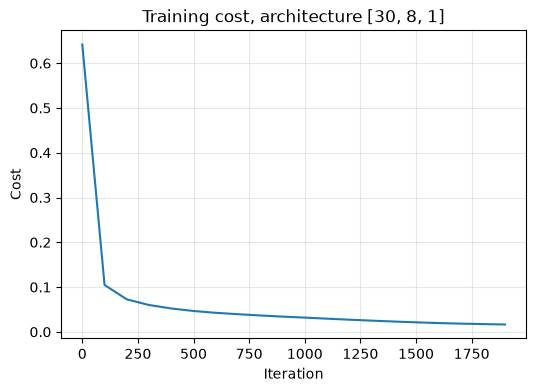

In [8]:
plt.figure(figsize=(6, 4))
plt.plot(np.arange(len(costs)) * 100, costs)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Training cost, architecture [30, 8, 1]")
plt.grid(alpha=0.3)
plt.show()

In [9]:
architectures = [
    [30, 1],
    [30, 4, 1],
    [30, 8, 1],
    [30, 16, 1],
    [30, 16, 8, 1],
]

rows = []
for dims in architectures:
    p, _ = train(X_train, Y_train, dims, lr=0.1, iterations=2000)
    rows.append({
        "Architecture": str(dims),
        "Train accuracy": round(accuracy(X_train, Y_train, p), 4),
        "Test accuracy": round(accuracy(X_test, Y_test, p), 4),
    })

results = pd.DataFrame(rows)
results

,Architecture,Train accuracy,Test accuracy
0,"[30, 1]",0.9890,0.9649
1,"[30, 4, 1]",0.9890,0.9561
2,"[30, 8, 1]",0.9956,0.9561
3,"[30, 16, 1]",0.9956,0.9649
4,"[30, 16, 8, 1]",1.0000,0.9561


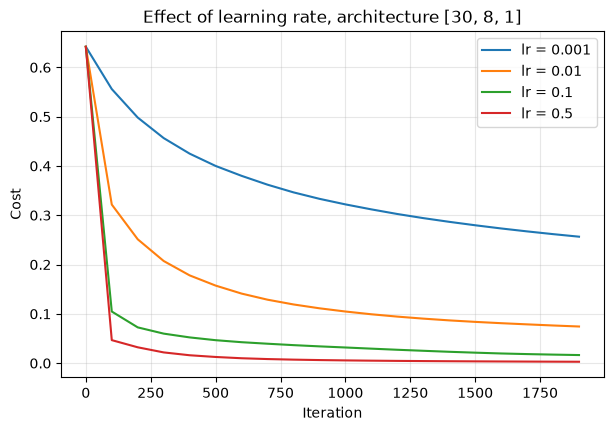

,Learning rate,Final cost,Test accuracy
0,0.001,0.2565,0.9123
1,0.010,0.0743,0.9474
2,0.100,0.0164,0.9561
3,0.500,0.0028,0.9561


In [10]:
plt.figure(figsize=(7, 4.5))
lr_rows = []
for lr in [0.001, 0.01, 0.1, 0.5]:
    p, c = train(X_train, Y_train, [30, 8, 1], lr=lr, iterations=2000)
    plt.plot(np.arange(len(c)) * 100, c, label=f"lr = {lr}")
    lr_rows.append({
        "Learning rate": lr,
        "Final cost": round(c[-1], 4),
        "Test accuracy": round(accuracy(X_test, Y_test, p), 4),
    })

plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Effect of learning rate, architecture [30, 8, 1]")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

pd.DataFrame(lr_rows)

In [11]:
baseline = LogisticRegression(max_iter=1000)
baseline.fit(X_train.T, y_train)

base_train = accuracy_score(y_train, baseline.predict(X_train.T))
base_test = accuracy_score(y_test, baseline.predict(X_test.T))

print(f"Logistic Regression  train: {base_train:.4f}   test: {base_test:.4f}")
print(f"My neural network    train: {accuracy(X_train, Y_train, params):.4f}   test: {accuracy(X_test, Y_test, params):.4f}")

Logistic Regression  train: 0.9890   test: 0.9825
My neural network    train: 0.9956   test: 0.9561


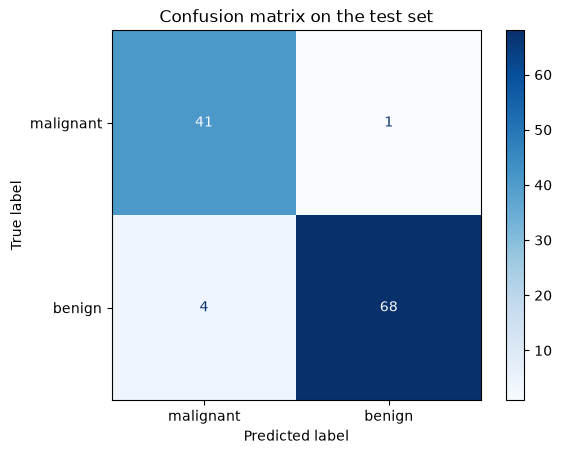

Malignant tumors predicted as benign (missed): 4
Benign tumors predicted as malignant (false alarm): 1


In [12]:
y_pred = predict(X_test, params).ravel()
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(cm, display_labels=["malignant", "benign"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix on the test set")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Malignant tumors predicted as benign (missed): {fn}")
print(f"Benign tumors predicted as malignant (false alarm): {fp}")